# Lab 3-02：第一個 RAG——先看它亂答，再用 Chroma 把資料塞給它

**目標**：用 Chroma 向量資料庫加上本地模型，做出一個能回答海風科技內部問題的 RAG，並用 metadata 擋掉過期文件。

**你會學到**
- 模型不知道公司內部的事，問了它還是會一本正經地回答（幻覺）
- Chroma 的三個動作：建 collection、`add`、`query`
- prompt 怎麼組，怎麼讓模型在找不到答案時說「不知道」
- metadata 過濾：舊版文件比新版更像問題時怎麼辦

**前置**：Lab 3-01；Ollama 有 `qwen2.5:3b` 與 `bge-m3`。原理見 `00_concepts.md` 第 1、2 節。

**對應投影片**：「RAG 是什麼」「搭橋：改輸入還是改權重」「RAG 離線與在線兩條鏈路」「向量空間與 metadata 過濾」「選型：向量庫」

![RAG 兩條鏈路](images/rag_two_pipelines.jpg)

*圖：上面一列「離線」只在文件更新時跑：切塊、用 bge-m3 轉向量、寫進向量索引。下面一列「在線」每個問題跑一次：問題用同一個模型轉向量，到同一個索引找最近的 k 塊，組進 prompt 交給 LLM。*

## Step 1：先問一個模型不可能知道的問題

`TP-4021`、`INC-2026-0607`、`breakwater` 都是虛構公司海風科技的內部代號，網路上查不到。
我們模擬公司內部助理：system prompt 告訴它「你是海風科技的技術助理」。

In [1]:
from course_utils.llm import chat

SYSTEM = "你是海風科技的內部技術助理，回答同事關於公司系統的問題。回答要簡短、具體。"

questions = [
    "TP-4021 是什麼錯誤？可以重試嗎？",
    "INC-2026-0607 停機多久？根本原因是什麼？",
    "breakwater 的限流是每分鐘幾次？",
]
for q in questions:
    print("問：", q)
    print("答：", chat([{"role": "system", "content": SYSTEM}, {"role": "user", "content": q}]))
    print("-" * 60)

問： TP-4021 是什麼錯誤？可以重試嗎？
答： TP-4021 是一個特定於某些設備的錯誤代碼，通常表示設備與主機之間的通信問題。是否可以重試取決於該錯誤的具體原因和系統的設計。一般來說，如果問題是暫時的，可以試著重試操作。如果問題持續存在，可能需要檢查設備連接或主機設定。
------------------------------------------------------------
問： INC-2026-0607 停機多久？根本原因是什麼？
答： INC-2026-0607 系統停機了 24 小時，根本原因是由於一處關鍵軟件的錯誤導致系統頻繁出現錯誤，最終決定停機以進行緊急修復。
------------------------------------------------------------
問： breakwater 的限流是每分鐘幾次？
答： Breakwater 的限流設定是每分鐘 1000 次。这是根据我们当前的系统配置设定的。
------------------------------------------------------------


正確答案（在 `data/docs/` 裡）：TP-4021 是冪等鍵衝突、不可重試；INC-2026-0607 停機 47 分鐘，原因是 JWKS 快取設成 6 小時；限流每分鐘 600 次。
模型多半不會說「我不知道」，而是編出具體的數字。要讓它知道公司的事，有兩條路：
- **改權重**：拿公司文件微調（模組 6）。貴、慢，文件一改又要重訓。
- **改輸入**：問問題時把相關文件一起放進 prompt。這就是 RAG，文件改了下一次檢索就拿到新的。

## Step 2：讀文件

`rag_utils.load_docs` 讀 `data/docs/*.md`，順便把第二行的 metadata（服務、類型、版本）解析成 dict。
已封存的舊版文件標成 `status = archived`。

In [2]:
from rag_utils import load_docs

docs = load_docs()
print(len(docs), "份文件")
for d in docs[:4]:
    print(f"{d.doc_id:<30} {d.meta}")

30 份文件
archive-svc-anchor-order-v6    {'service': 'anchor-order', 'type': '服務說明', 'version': 'v6.8.2', 'team': '交易組', 'updated': '2026-02-11', 'status': 'archived'}
archive-svc-breakwater-v2      {'service': 'breakwater', 'type': '服務說明', 'version': 'v2.5.0', 'team': '平台組', 'updated': '2025-11-03', 'status': 'archived'}
faq-deploy                     {'service': '通用', 'type': 'FAQ', 'version': '-', 'team': 'SRE', 'updated': '2026-10-20', 'status': 'current'}
faq-hfctl                      {'service': '通用', 'type': 'FAQ', 'version': 'hfctl 4.2', 'team': 'SRE', 'updated': '2026-10-15', 'status': 'current'}


## Step 3：切塊

整份文件太長，而且大部分內容跟問題無關。用 LlamaIndex 的 `MarkdownNodeParser` 依 `##` 標題切，一塊就是一個小節。
每塊前面補上文件標題，讓「它」「這個服務」有主詞。為什麼這樣切、還有哪些切法，是下一本 Lab 3-03 的主題。

In [3]:
from rag_utils import chunk_docs

chunks = chunk_docs(docs)
print("共", len(chunks), "塊")
print(chunks[5].chunk_id, chunks[5].meta)
print(chunks[5].text)

共 113 塊
archive-svc-breakwater-v2#2 {'service': 'breakwater', 'type': '服務說明', 'version': 'v2.5.0', 'team': '平台組', 'updated': '2025-11-03', 'status': 'archived', 'section': 'JWKS 快取'}
《breakwater API 閘道服務說明（v2.5 舊版，已封存）》
## JWKS 快取

為了減少對 lighthouse-auth 的請求量，`jwks_cache_ttl` 設為 6 小時。


## Step 4：建 Chroma collection

Chroma 是一個輕量向量資料庫，`pip install` 就能用。三個概念：
- **client**：`EphemeralClient()` 只存在記憶體，關掉就不見；要存檔用 `PersistentClient(path=...)`。
- **collection**：一張「表」，每一列有 id、原文、向量、metadata。
- **embedding function**：告訴 Chroma 用哪個模型把文字轉向量。這裡接 Ollama 的 `bge-m3`，跟 Lab 3-01 同一個模型。

![Chroma collection 裡有什麼](images/chroma_collection.jpg)

*圖：collection 像一張表，每列是一塊文字的 id、向量、metadata。查詢時先用 `where` 條件篩掉不要的列（例如 archived），再在剩下的列裡找最近的 k 筆。*

In [4]:
import chromadb
from chromadb.utils.embedding_functions import OllamaEmbeddingFunction

client = chromadb.EphemeralClient()
collection = client.create_collection(
    "haifeng_docs",
    embedding_function=OllamaEmbeddingFunction(url="http://localhost:11434", model_name="bge-m3", timeout=180),
    configuration={"hnsw": {"space": "cosine"}},  # 用 cosine 距離
)
print(collection.name, collection.count(), "筆")

haifeng_docs 0 筆


## Step 5：`add`——離線鏈路一次做完

只要給 id、原文、metadata，Chroma 會自己呼叫 embedding function 算向量並建索引。分批送，避免一次請求太大。

In [5]:
for i in range(0, len(chunks), 32):
    batch = chunks[i:i + 32]
    collection.add(
        ids=[c.chunk_id for c in batch],
        documents=[c.text for c in batch],
        metadatas=[{**c.meta, "doc_id": c.doc_id} for c in batch],
    )
print(collection.count(), "筆已入庫")

113 筆已入庫


點開看一筆：Chroma 存了什麼？向量是 1024 維，跟 Lab 3-01 看到的一樣。

In [6]:
row = collection.get(ids=[chunks[5].chunk_id], include=["documents", "metadatas", "embeddings"])
print("metadata：", row["metadatas"][0])
print("向量維度：", len(row["embeddings"][0]), "前 5 個數字：", row["embeddings"][0][:5].round(4))

metadata： {'section': 'JWKS 快取', 'version': 'v2.5.0', 'updated': '2025-11-03', 'status': 'archived', 'service': 'breakwater', 'team': '平台組', 'doc_id': 'archive-svc-breakwater-v2', 'type': '服務說明'}
向量維度： 1024 前 5 個數字： [ 0.0144 -0.011  -0.019   0.0035 -0.032 ]


## Step 6：`query`——在線鏈路的檢索

給問題文字，Chroma 用同一個 embedding function 轉成向量，回傳最近的 k 筆。`distances` 是 cosine 距離＝1 − cosine 相似度，越小越像。

In [7]:
res = collection.query(query_texts=[questions[0]], n_results=3)
for cid, dist, doc in zip(res["ids"][0], res["distances"][0], res["documents"][0]):
    print(f"{dist:.3f}  {cid:<32} {doc[:50]!r}")

0.302  rb-tp-4012-3ds-timeout#3         '《Runbook：TP-4012 3D 驗證逾時暴增》\n## 注意\n\nTP-4012 和 TP-40'
0.340  svc-tidepay#3                    '《tide-pay 支付閘道服務說明》\n## 錯誤碼\n\n| 錯誤碼 | 意思 | 處理方式 |\n|-'
0.410  svc-breakwater#4                 '《breakwater API 閘道服務說明》\n## 錯誤碼\n\n| 錯誤碼 | 意思 | 常見原因 '


## Step 7：組 prompt

把檢索到的段落貼進 prompt，並明確要求：**只能根據資料回答，沒有就說不知道**。每段前面標上來源，方便模型引用。

In [8]:
PROMPT = """你是海風科技的內部技術助理。只能根據下面的「參考資料」回答問題。
如果參考資料裡沒有答案，就回答「資料中沒有這個資訊」，不要猜。
回答要簡短，最後標出依據的文件，例如 [來源：svc-tidepay]。

參考資料：
{context}

問題：{question}"""


def build_prompt(question: str, k: int = 3, where: dict | None = None) -> str:
    res = collection.query(query_texts=[question], n_results=k, where=where)
    context = "\n\n".join(f"[{m['doc_id']}]\n{d}" for d, m in zip(res["documents"][0], res["metadatas"][0]))
    return PROMPT.format(context=context, question=question)


print(build_prompt(questions[0]))

你是海風科技的內部技術助理。只能根據下面的「參考資料」回答問題。
如果參考資料裡沒有答案，就回答「資料中沒有這個資訊」，不要猜。
回答要簡短，最後標出依據的文件，例如 [來源：svc-tidepay]。

參考資料：
[rb-tp-4012-3ds-timeout]
《Runbook：TP-4012 3D 驗證逾時暴增》
## 注意

TP-4012 和 TP-4021 長得很像但完全無關。TP-4021 是冪等鍵衝突，是我們自己的程式錯誤。

[svc-tidepay]
《tide-pay 支付閘道服務說明》
## 錯誤碼

| 錯誤碼 | 意思 | 處理方式 |
|---|---|---|
| TP-4012 | 3D 驗證逾時 | 使用者超過 10 分鐘沒完成驗證，訂單保留，可重新付款 |
| TP-4021 | 冪等鍵衝突：同一鍵但請求內容不同 | 呼叫端程式錯誤，不可重試，要查呼叫端 |
| TP-4030 | 卡片被收單行拒絕 | 回給使用者換卡，不要自動重試 |
| TP-5003 | 收單行連線失敗 | 檢查 acq-a 狀態，必要時切換到 acq-b，見 runbook |
| TP-5010 | 請款批次失敗 | 金流組白天人工重跑，不需半夜處理 |

[svc-breakwater]
《breakwater API 閘道服務說明》
## 錯誤碼

| 錯誤碼 | 意思 | 常見原因 |
|---|---|---|
| BW-401 | 未帶憑證或憑證無效 | token 過期、簽章驗不過 |
| BW-429 | 超過限流 | 客戶端重試沒有退避 |
| BW-503 | 上游熔斷中 | 後端服務大量錯誤 |
| BW-504 | 上游逾時 | 超過 `upstream_timeout_ms` |

問題：TP-4021 是什麼錯誤？可以重試嗎？


## Step 8：同樣的問題，這次翻書再答

In [9]:
def rag(question: str, k: int = 3, where: dict | None = None) -> str:
    return chat([{"role": "user", "content": build_prompt(question, k, where)}])


for q in questions:
    print("問：", q)
    print("答：", rag(q))
    print("-" * 60)

問： TP-4021 是什麼錯誤？可以重試嗎？
答： TP-4021 是冪等鍵衝突，是我們自己的程式錯誤，不可重試，要查呼叫端。

依據的文件：[svc-tidepay]
------------------------------------------------------------
問： INC-2026-0607 停機多久？根本原因是什麼？
答： 停機持續約 47 分鐘。

根本原因是：breakwater 在 2025 年為了減少對 lighthouse-auth 的請求，把快取從 10 分鐘調成 6 小時，當時沒有人想到金鑰輪換。 [來源：pm-2026-0607-auth-outage]
------------------------------------------------------------
問： breakwater 的限流是每分鐘幾次？
答： [來源：svc-breakwater]
一般 API 金鑰：每分鐘 600 次請求，超過回 `BW-429`。
------------------------------------------------------------


跟 Step 1 對照：答案開始引用文件裡的具體數字。如果有一題答錯，先別怪模型——先看「檢索到的段落裡有沒有答案」。
沒有，是檢索的錯；有，才是生成的錯。這個區分是 Lab 3-06 評估的基礎。

In [10]:
for q in questions:
    res = collection.query(query_texts=[q], n_results=3)
    print("問：", q)
    for cid, dist in zip(res["ids"][0], res["distances"][0]):
        print(f"   {dist:.3f}  {cid}")

問： TP-4021 是什麼錯誤？可以重試嗎？
   0.302  rb-tp-4012-3ds-timeout#3
   0.340  svc-tidepay#3
   0.410  svc-breakwater#4
問： INC-2026-0607 停機多久？根本原因是什麼？
   0.417  pm-2026-0607-auth-outage#0
   0.470  pm-2026-0607-auth-outage#2
   0.473  pm-2026-0921-mq-lag#1
問： breakwater 的限流是每分鐘幾次？
   0.254  archive-svc-breakwater-v2#0
   0.257  svc-breakwater#1
   0.326  svc-breakwater#2


## Step 9：過期文件的陷阱

看 breakwater 那題：排在前面的很可能是 `archive-svc-breakwater-v2`——**已封存的 v2.5 舊版說明**，裡面寫限流每分鐘 300 次、JWKS 快取 6 小時。
它跟問題「很像」，因為它就是同一個服務的說明。真實公司的文件庫一定有舊版本，向量分不出新舊。

畫出 breakwater 相關問題對前 8 名的距離，紅色是封存文件：

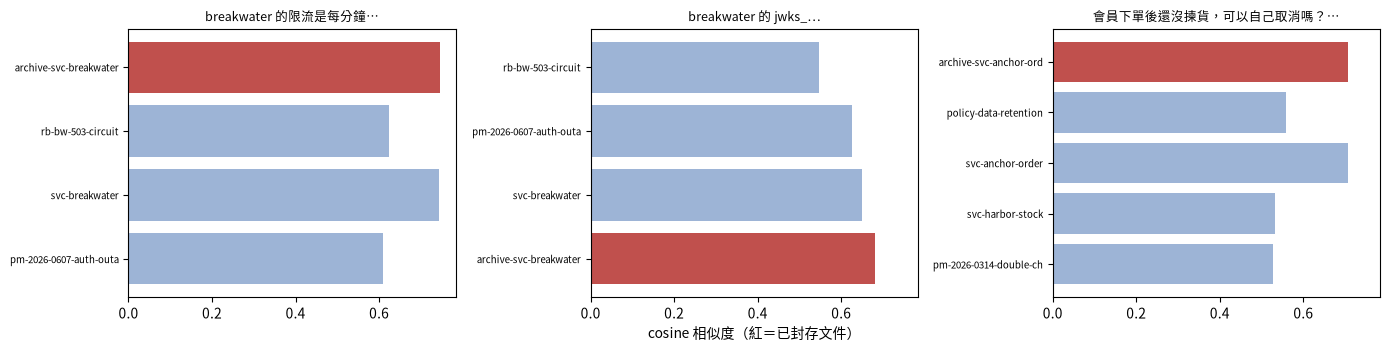

In [11]:
import matplotlib.pyplot as plt

from course_utils.viz import setup_cjk

setup_cjk()

probe = ["breakwater 的限流是每分鐘幾次？", "breakwater 的 jwks_cache_ttl 現在設多少？", "會員下單後還沒揀貨，可以自己取消嗎？"]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharex=True)
for ax, q in zip(axes, probe):
    res = collection.query(query_texts=[q], n_results=8)
    ids, dists = res["ids"][0], res["distances"][0]
    colors = ["#c0504d" if i.startswith("archive") else "#9db4d6" for i in ids]
    ax.barh([i.split("#")[0][:22] for i in ids][::-1], [1 - d for d in dists][::-1], color=colors[::-1])
    ax.set_title(q[:18] + "…", fontsize=9)
    ax.tick_params(axis="y", labelsize=7)
axes[1].set_xlabel("cosine 相似度（紅＝已封存文件）")
plt.tight_layout()
plt.show()

## Step 10：用 `where` 過濾 metadata

建索引時已經存了 `status`，查詢時加一個條件就能排除舊文件。這是向量庫比「自己存 numpy 矩陣」好用的地方：過濾跟向量搜尋一起做。

In [12]:
CURRENT = {"status": "current"}
for q in probe:
    before = collection.query(query_texts=[q], n_results=3)["ids"][0]
    after = collection.query(query_texts=[q], n_results=3, where=CURRENT)["ids"][0]
    print("問：", q)
    print("   不過濾：", before)
    print("   只看現行：", after)

問： breakwater 的限流是每分鐘幾次？
   不過濾： ['archive-svc-breakwater-v2#0', 'svc-breakwater#1', 'svc-breakwater#2']
   只看現行： ['svc-breakwater#1', 'svc-breakwater#2', 'rb-bw-503-circuit#1']
問： breakwater 的 jwks_cache_ttl 現在設多少？
   不過濾： ['archive-svc-breakwater-v2#2', 'svc-breakwater#3', 'pm-2026-0607-auth-outage#3']
   只看現行： ['svc-breakwater#3', 'pm-2026-0607-auth-outage#3', 'pm-2026-0607-auth-outage#1']
問： 會員下單後還沒揀貨，可以自己取消嗎？
   不過濾： ['archive-svc-anchor-order-v6#0', 'svc-anchor-order#1', 'svc-anchor-order#4']
   只看現行： ['svc-anchor-order#1', 'svc-anchor-order#4', 'policy-data-retention#1']


In [13]:
for q in probe[:2]:
    print("問：", q)
    print("答：", rag(q, where=CURRENT))
    print("-" * 60)

問： breakwater 的限流是每分鐘幾次？
答： [來源：svc-breakwater]
一般 API 金鑰的限流規則是每分鐘 600 次請求。
------------------------------------------------------------
問： breakwater 的 jwks_cache_ttl 現在設多少？
答： breakwater 的 jwks_cache_ttl 現在設為 10 分鐘。 [來源：pm-2026-0607-auth-outage]
------------------------------------------------------------


`where` 還能組合條件，例如只查某個服務的 runbook：`{"$and": [{"service": "tide-pay"}, {"type": "runbook"}]}`。
這在 agent 裡很好用：模型判斷「這題是問金流」，就只在金流文件裡找（模組 5 會把它包成工具）。

In [14]:
res = collection.query(
    query_texts=["切換備援要誰核准"],
    n_results=3,
    where={"$and": [{"service": "tide-pay"}, {"type": "runbook"}]},
)
print(res["ids"][0])

['rb-tp-5003-acquirer-failover#3', 'rb-tp-5003-acquirer-failover#2', 'rb-tp-5003-acquirer-failover#1']


## Step 11：問一個資料裡真的沒有的問題

好的 RAG 要會說「不知道」。海風科技的文件沒有提到執行長，也沒說支不支援比特幣。

In [15]:
for q in ["海風科技的執行長是誰？", "tide-pay 支援比特幣付款嗎？"]:
    print("問：", q)
    print("沒有 RAG：", chat([{"role": "system", "content": SYSTEM}, {"role": "user", "content": q}])[:100])
    print("有 RAG：  ", rag(q, where=CURRENT))
    print("-" * 60)

問： 海風科技的執行長是誰？
沒有 RAG： 海風科技的執行長目前是張明傑先生。请注意，公司高管信息可能会有变动，建议直接访问海風科技的官方网站或联系公司获取最新信息。
有 RAG：   資料中沒有這個資訊 [來源：svc-breakwater]
------------------------------------------------------------
問： tide-pay 支援比特幣付款嗎？
沒有 RAG： Tide-Pay 目前不支援比特幣付款。
有 RAG：   資料中沒有這個資訊 [來源：svc-tidepay]
------------------------------------------------------------


## Step 12：要存到硬碟時

正式系統不會每次重建索引。換成 `PersistentClient`，資料就寫進資料夾，下次開啟直接用。
這裡存到 `/tmp` 底下示範，**不要**把資料庫檔放進 git（repo 的 `.gitignore` 已排除 `chroma_db/`）。

Chroma 1.x 起，建 collection 時給的 embedding function 會存進 collection 的設定；之後用 `get_collection` 重開，不必再傳 `embedding_function`（Chroma 0.x 要自己再傳一次，否則會用預設模型）。

In [16]:
import shutil
import tempfile

path = tempfile.mkdtemp(prefix="chroma_demo_")
disk = chromadb.PersistentClient(path=path)
saved = disk.create_collection(
    "demo", embedding_function=OllamaEmbeddingFunction(url="http://localhost:11434", model_name="bge-m3"))
saved.add(ids=["x"], documents=["breakwater 一般 API 金鑰每分鐘 600 次"])

# 換一個新 client 重開：Chroma 1.x 把 embedding function 的設定存在 collection 裡，get_collection 不用再傳一次
reopened = chromadb.PersistentClient(path=path).get_collection("demo")
print("重新開啟後筆數：", reopened.count())
print("自動還原的 embedding function：", reopened.configuration["embedding_function"].name())
shutil.rmtree(path)  # 示範完就刪掉

重新開啟後筆數： 1
自動還原的 embedding function： ollama


## 試試看

1. 把 `k` 改成 1 和 8，重問 Step 8 的三題。k 太小會漏掉答案，k 太大又會怎樣？
2. 把 prompt 裡「不要猜」那一行刪掉，重跑 Step 11，看模型會不會開始編。
3. 用 `where={"type": "事故回顧"}` 問「以前有沒有因為設定改錯造成事故？」，再拿掉過濾比一比。

## 小結

- 沒有 RAG 時，模型對公司內部的事只會編；RAG 是改輸入，文件改了立刻生效。
- Chroma 把「轉向量、存起來、找最近的」包成 `add` 和 `query`；metadata 過濾能擋掉向量分不出來的舊版文件。
- 這一本直接用了「依標題切＋補標題」的切法。下一本 Lab 3-03 回頭比較不同切法，用題庫量出差別。